<a href="https://colab.research.google.com/github/diosthenes/langevin-dynamics/blob/main/Langevin_Smooth_Potential.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [72]:
import numpy as np
import matplotlib.pyplot as plt

In [73]:
#Partiicle and Simualtion parameters
n = 100 #number of particles
x = np.linspace(-40, 40, 10000) #x-grid
x_particles = np.full(n, 30.0) #Initial particle position
t_start = 0
t_stop = 10000
dt = 1e-3
n_steps = int(((t_stop - t_start)/dt)) #steps fpr numerical integration

In [74]:
#Physical constants
kB = 1.0
gamma = 1.0
#potential parameters
a_pot = 30
r_pot = 2
D_pot = 5
L_pot = a_pot + r_pot
k_pot = 5
#temperature parameters
T_1 = 200
T_2 = 100
a_temp = 100/56 #temp gradient
c_temp = (T_1 + T_2)/2

In [75]:
#Potential Function
def V(x):
  V = np.piecewise(x, [x<-32,  (-32<=x) & (x<=-28), (-28<x) & (x<28), (28<=x) & (x<=32), (32<x)],
                  [lambda x: k_pot * (x + L_pot)**2, lambda x: -D_pot * (1 - ((x + a_pot)/2)**2)**2, 0,
                   lambda x: -D_pot * (1 - ((x - a_pot)/2)**2)**2, lambda x: k_pot * (x - L_pot)**2])
  return V

In [76]:
#Temperature function
def T(x):
  T = np.piecewise(x, [x<-28, (-28<=x) & (x<=28), 28<x], [T_2, lambda x: a_temp * x + c_temp, T_1])
  return T

In [77]:
#Potential Gradient
def dV_dx(x):
  dV_dx = np.piecewise(x, [x<-32, (-32<=x) & (x<=-28), (-28<x) & (x<28), (28<=x) & (x<=32), (32<x)],
                       [lambda x: 2*k_pot*(x + L_pot), lambda x: 2 * D_pot * ((x + 30)/2) * (1-((x + 30)/2)**2), 0,
                        lambda x: 2 * D_pot * ((x - 30)/2) * (1-((x - 30)/2)**2), lambda x: 2 * k_pot * (x - L_pot)])
  return dV_dx

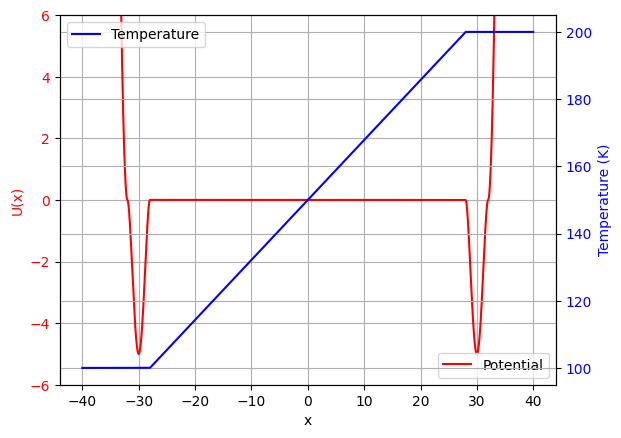

In [78]:
#plot of temperature and potential
fig, ax1 = plt.subplots()
#potential
ax1.plot(x, V(x), color='red', label='Potential')
ax1.set_xlabel('x')
ax1.set_ylabel('U(x)', color='red')
ax1.set_ylim(-6, 6)
ax1.tick_params(axis='y', labelcolor='red')
ax1.grid()
ax1.legend(loc='lower right')
#temperature
ax2 = ax1.twinx()
ax2.plot(x, T(x), color='blue', label='Temperature')
ax2.set_ylabel('Temperature (K)', color='blue')
ax2.grid()
ax2.tick_params(axis='y', labelcolor='blue')
ax2.legend()

In [79]:
#Euler-Maruyama integration
for i in range(n_steps):
  T_particle = T(x_particles)
  noise_amp = np.sqrt(2*kB*T_particle/gamma)
  N_t = np.random.randn(n)
  F_ext = (-1/gamma) * (dV_dx(x_particles))
  x_particles = x_particles + F_ext*dt + noise_amp*N_t*np.sqrt(dt)

print(x_particles)

[-29.71975439 -16.35521363 -27.51408667  28.17720984   5.15161576
 -34.40961604  -9.09492174 -24.69374531 -13.82683125 -30.92792598
  -3.48642165 -29.24922866  -9.01078797  -5.63826192   3.46602794
 -26.81989502 -14.27298887 -33.68098742 -33.93764975 -11.4414936
 -32.01750363  -7.61485169  30.11110565   9.71138274  -7.01936822
  -3.32939166 -31.59184028   3.34333894 -28.76698766  -1.75159273
   3.76973227  14.78863313  12.27937536 -35.96823858 -35.86763615
 -21.23529632   3.35596483 -21.16948659  16.31729525  -5.59558762
 -24.85927026 -30.86053308  11.68564028  -5.76875839  -6.75610159
  11.55514235  17.21011238   4.76407056   0.08239604  -8.80050634
 -28.85327491  -1.20654284  -1.03592728  -0.90664541  18.54627371
  35.88668186 -23.72534758  11.318265     9.95612725 -29.18326331
   5.53916928   6.6084217  -20.49020146 -33.76924375   7.66098045
 -10.05328478  10.02783604  -0.72584137 -26.10414439  23.36044869
 -21.79904206  34.0275541  -24.12374618  37.71414823   9.09336367
   0.236081

In [80]:
#Theoretical probability density
def P(x):
  D_inv = gamma/(kB*T(x))
  exp = V(x)/(kB*T(x))
  P = D_inv * np.exp(-exp)
  return P

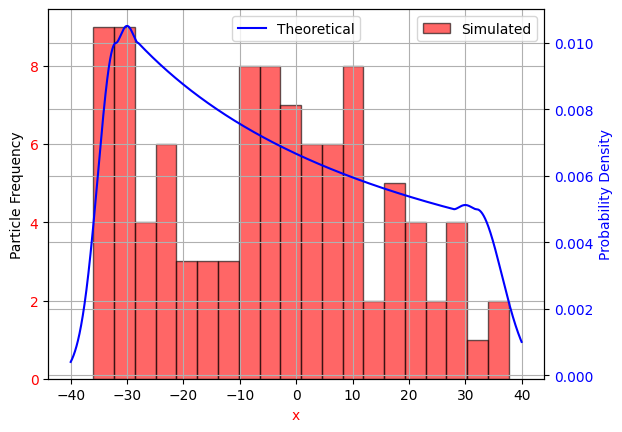

In [81]:
fig, ax1 = plt.subplots()
#Histogram
ax1.hist(x_particles, bins=20, color='red', alpha=0.6, edgecolor='black', label='Simulated')
ax1.set_xlabel('x', color='red')
ax1.set_ylabel('Particle Frequency')
ax1.grid()
ax1.legend()
ax1.tick_params(axis='y', labelcolor='red')
#Theoretical probability density plot
ax2 = ax1.twinx()
ax2.plot(x, P(x), color='blue', label='Theoretical')
ax2.set_ylabel('Probability Density', color='blue')
ax2.grid()
ax2.legend(loc='upper center')
ax2.tick_params(axis='y', labelcolor='blue')